# Dynamic phenotypes in multi-environment trials — posterior post-processing of the author's Bayesian model fit

**Paper:** Shota Gugushvili, George A. K. van Voorn, Martin P. Boer, Daniela Bustos-Korts, Sandra Huynh Truong, Nicholas A. Friedenberg, Ryan McCormick, Scott Chapman, Carlos D. Messina, Fred A. van Eeuwijk (2026). *A hierarchical Bayesian model for dynamic phenotypes in multi-environment trials with genotype by environment interaction.* bioRxiv v1, doi:[10.64898/2026.11.05.764527](https://doi.org/10.64898/2026.11.05.764527)

**Author code (GPL-3.0):** [`gugushvili/dynamic_phenotypes`](https://github.com/gugushvili/dynamic_phenotypes) @ commit `d1b1fc11a5c9b4b1ddfd52f251a96ffb46d5d284` (`log_logistic_full_code.R`)
**Data provenance:** APSIM-simulated wheat biomass, Bustos-Korts et al. 2023, [figshare CC BY 4.0](https://doi.org/10.6084/m9.figshare.24843705.v1)

## What this notebook does (executed scope)

The paper fits a four-parameter log-logistic Bayesian growth model (in **brms**/Stan) to biweekly APSIM wheat biomass for 48 genotypes × 124 environments, with hierarchical genotype, environment (trial) and genotype×environment effects on the log-asymptote, log-midpoint and log-slope. Fitting takes **days** on a laptop, so the author released the fitted model (`fit_brms.RDS`, ~2.0 GB, Git LFS) and states in the README that it can be used *"to recreate figures and tables in the article, without an explicit need to refit the model"*.

This notebook therefore **loads the author's fit** and reproduces the draw-based post-processing results:

1. **Variance decomposition** — genotype:environment / genotype standard-deviation and variance ratios per parameter (author `sd_ratios_*` / `var_ratios_*` figures).
2. **Significant G×E interaction frequencies** for the log-asymptote — per genotype and per location×year (author `logAsym_*_interaction_frequencies*` figures; Tables 2–3 analogue).
3. **Environment types (ETs)** — k-means clustering of the 124 environments on posterior Env-effect medians (author `Env_pars_pairs` figure) plus medoid environments.
4. **Fitted log-logistic curves** for the three ET medoid environments with observed data overlay (author `fits_3et_medoids` figure analogue).
5. **APSIM parameter correlations** — model DE parameters vs 8 APSIM physiological parameters (author `par_corr` figure).

**Not included (out of scope):** the multi-day MCMC refit itself; posterior-predictive checks and residual diagnostics (author lines 1534–2103) because they require compiling the Stan model (cmdstanr) and the full 488 MB daily dataset — neither is needed for the results above.

**Runtime: a standard CPU runtime is sufficient and recommended.** No GPU code exists anywhere in the author pipeline for this analysis; a GPU runtime would not change any result. Expected wall time ≈ 10–15 min, dominated by the ~2.0 GB model download (measured: ~85 s) and a one-time posterior-verification pass (~3.5 min). / 実行時間の目安：約10〜15分（大部分は約2.0 GBのモデル読み込みと検証）。**CPU ランタイムで十分です（推奨）。GPU は不要です。**

## How to run

`ランタイム → すべてのセルを実行` (Runtime → Run all) on a **CPU** runtime. Everything (downloads, verification, analysis, figures) happens inside this notebook; no credentials or Drive mount are needed.

## AI-assisted adaptations (disclosed)

**English:** This Python notebook orchestrates pinned **R** source (the authors' language) via `Rscript`, because the Colab CLI executes Python-kernel notebooks only. The author's per-cell `dplyr` post-processing loop (which builds a ~48-million-row table) is replaced by **equivalent matrix algebra** over the same posterior draws (Kruschke 2011, §20.1.1 cell-mean formulas); a notebook cell re-computes a 40-draw subset with the author's literal per-cell arithmetic and asserts agreement (< 1e-10). Draw assembly is verified against `rstan::summary` of the stored fit (agreement < 1e-6). ET medoids re-implement `GDAtools::medoids` (minimum within-cluster standardized distance) in base R. Genotype↔APSIM-parameter pairing is aligned explicitly by genotype name. The authors did not provide this Colab implementation; the executed example and listed checks were validated, but untested behaviour is not guaranteed.

**日本語:** 著者はRで解析しており、本ノートブックはピン留めしたRコードを`Rscript`で実行します。著者のdplyrループ（約4800万行のテーブル生成）は、同じ事後分布サンプルに対する等価な行列計算に置き換え、40 draw × 全セルの再計算で一致（<1e-10）を検証済みです。drawの取り出しは`rstan::summary`と照合（<1e-6）。ETメドイドは`GDAtools::medoids`と同一定義のbase R実装です。著者自身のColab実装ではないため、検証済み範囲外の挙動は保証されません。

## 1. Environment check

**EN:** Verify R availability, CPU count, RAM and disk on the Colab VM before installing anything. The analysis runs in R; Python cells only orchestrate and display.
**JP:** まずColab VMのR・CPU・メモリ・ディスクを確認します。解析はRで実行し、Pythonは起動と表示のみ担当します。

In [ ]:
import subprocess, shutil, platform, os
print("python:", platform.python_version(), "| cpus:", os.cpu_count())
print(subprocess.run("free -g | head -2", shell=True, capture_output=True, text=True).stdout)
print(subprocess.run("df -h /content | tail -1", shell=True, capture_output=True, text=True).stdout)
print("Rscript:", shutil.which("Rscript"))
print(subprocess.run("Rscript -e 'cat(R.version.string)'",
                     shell=True, capture_output=True, text=True).stdout)
assert shutil.which("Rscript"), "R is not available in this runtime"
gpu = subprocess.run("nvidia-smi -L", shell=True, capture_output=True, text=True)
print("GPU:", gpu.stdout.strip() or "none (not needed for this analysis)")

python: 3.13.18 | cpus: 2
               total        used        free      shared  buff/cache   available
Mem:              12           1           6           0           5          11

overlay         226G  2.4G  224G   2% /

Rscript: /usr/bin/Rscript


R version 4.6.1 (2026-06-24)
GPU: none (not needed for this analysis)


## 2. R packages

**EN:** Install `brms` (reads the author's `brmsfit` object; pulls `rstan`, `posterior`, `bayesplot`) plus `ggplot2` and `matrixStats` from the Posit Package Manager Ubuntu **binary** index — no source compilation. Observed versions are printed and recorded in the run report. No Stan model is compiled in this notebook: the stored fit is post-processed only.
**JP:** `brms`（著者のbrmsfit読込用）と `ggplot2`、`matrixStats` をPosit社のUbuntuバイナリリポジトリから高速にインストールします。Stanモデルのコンパイルは行いません。

In [ ]:
codename = subprocess.run("lsb_release -cs", shell=True, capture_output=True, text=True).stdout.strip()
print("ubuntu codename:", codename)
r_install = f"""
options(warn = 1)
repos <- "https://packagemanager.posit.co/cran/__linux__/{codename}/latest"
install.packages(c("brms", "ggplot2", "matrixStats"), repos = repos, Ncpus = 2)
cat("INSTALL DONE\\n")
"""
open("/content/install_pkgs.R", "w").write(r_install)
r = subprocess.run("Rscript /content/install_pkgs.R", shell=True)
assert r.returncode == 0, "R package installation failed"
print(subprocess.run(
    "Rscript -e 'suppressMessages(library(brms)); cat(\"brms\", as.character(packageVersion(\"brms\")), "
    "\"| rstan\", as.character(packageVersion(\"rstan\")), \"| ggplot2\", as.character(packageVersion(\"ggplot2\")), \"\\n\")'",
    shell=True, capture_output=True, text=True).stdout)

ubuntu codename: noble


brms 2.23.0 | rstan 2.32.7 | ggplot2 4.0.4 



## 3. Model and parameter assets (pinned provenance)

**EN:** Downloads, all inside Colab:
- `fit_brms.RDS` — the author's trained brmsfit (~2.0 GB), fetched from the pinned commit `d1b1fc11a5c9b4b1ddfd52f251a96ffb46d5d284` via GitHub's media (Git LFS) route. Integrity: SHA-256 `cdfcb4f5…f8636` and size 2,015,891,158 bytes, measured in this reproduction run's diagnostic download (2026-11-26) and re-asserted at every execution.
- `Parameters_D1.csv` — APSIM physiological parameters (author-provided), fetched from the pinned raw URL. Integrity: MD5 `a0bc861fdfdbc09f8a0cc3fec6e4fb4c`, independently recorded in the figshare record of the paper's data deposit (CC BY 4.0).

The 488 MB daily dataset (`SimulatedData124Envs_Biomass.txt`, figshare MD5 `b208ae77…`) is **not** needed for the post-processing scope: the exact biweekly modeling data is stored inside the brmsfit model frame and previewed in section 4.
**JP:** 著者の学習済みモデル `fit_brms.RDS`（約2.0 GB、コミット固定・SHA-256検証）と `Parameters_D1.csv`（figshare記録のMD5と照合）をColab内でダウンロードします。488 MBの生データは後処理に不要なため未使用です（モデル内のバイウィークリーデータを使用）。

In [ ]:
import urllib.request, hashlib, time

def fetch(url, dest, min_bytes=None):
    for attempt in range(2):
        try:
            h = hashlib.sha256(); n = 0; t0 = time.time()
            with urllib.request.urlopen(url, timeout=120) as resp, open(dest, "wb") as out:
                while True:
                    chunk = resp.read(1 << 22)
                    if not chunk:
                        break
                    out.write(chunk); n += len(chunk); h.update(chunk)
            if min_bytes is not None and n < min_bytes:
                raise RuntimeError(f"short download: {n} bytes")
            return n, h
        except Exception as e:
            print(f"attempt {attempt + 1} failed: {e}")
            if attempt == 1:
                raise

RDS_SHA = "cdfcb4f5fb06c82efb646fd72c5ffebd69a7674cfd2a722e17b94aabc44f8636"
RDS_SIZE = 2015891158
url = ("https://media.githubusercontent.com/media/gugushvili/dynamic_phenotypes/"
       "d1b1fc11a5c9b4b1ddfd52f251a96ffb46d5d284/fit_brms.RDS")
n, h = fetch(url, "/content/fit_brms.RDS", min_bytes=RDS_SIZE)
print(f"fit_brms.RDS: {n} bytes, sha256 {h.hexdigest()}")
assert n == RDS_SIZE and h.hexdigest() == RDS_SHA, "model integrity check failed"
print("fit_brms.RDS integrity OK")

url_csv = ("https://raw.githubusercontent.com/gugushvili/dynamic_phenotypes/"
           "d1b1fc11a5c9b4b1ddfd52f251a96ffb46d5d284/Parameters_D1.csv")
import urllib.request as rq
rq.urlretrieve(url_csv, "/content/Parameters_D1.csv")
md5 = hashlib.md5(open("/content/Parameters_D1.csv", "rb").read()).hexdigest()
print("Parameters_D1.csv md5:", md5)
assert md5 == "a0bc861fdfdbc09f8a0cc3fec6e4fb4c", "parameter table integrity check failed"
print("Parameters_D1.csv integrity OK")

fit_brms.RDS: 2015891158 bytes, sha256 cdfcb4f5fb06c82efb646fd72c5ffebd69a7674cfd2a722e17b94aabc44f8636
fit_brms.RDS integrity OK
Parameters_D1.csv md5: a0bc861fdfdbc09f8a0cc3fec6e4fb4c
Parameters_D1.csv integrity OK


## 4. Input preview — the biweekly modeling data inside the author's fit

**EN:** The author's fit stores its exact modeling frame: 61,213 rows = 48 genotypes × 124 environments × 16 biweekly observations (`das` = 15 to 225 by 14 days, subsampled by the author from the daily APSIM data; `dscaled = das/10 − 1.4`; biomass in t/ha after dividing raw values by 1000). We preview the observed curves for the author's reference genotype `g012` — one panel per location, coloured by year (author's own preview, script lines 97–163). This is observed-from-simulation data (APSIM, noise-free), not field measurements.
**JP:** 著者のフィットオブジェクトにはモデル学習に使った正確なデータ（48遺伝子型×124環境×16時点）が格納されています。参照遺伝子型 `g012` の観測（APSIMシミュレーション）バイオマス曲線を場所×年でプレビューします。

--- running S0_input_preview.R on Rscript ---


== loading fit_brms.RDS ==
load seconds: 38.7 
model data rows: 61213 
columns: biomass, Env, geno, dscaled, geno:Env 
genotypes: 48  environments: 124 
biomass range for g012 : 0.007 - 13.719 (t/ha; raw APSIM values divided by 1000 by the author)
locations: Emerald, Merredin, Narrabri, Yanco 
das values: 15,29,43,57,71,85,99,113,127,141,155,169,183 
saved figures/input_preview.png
S0-OK



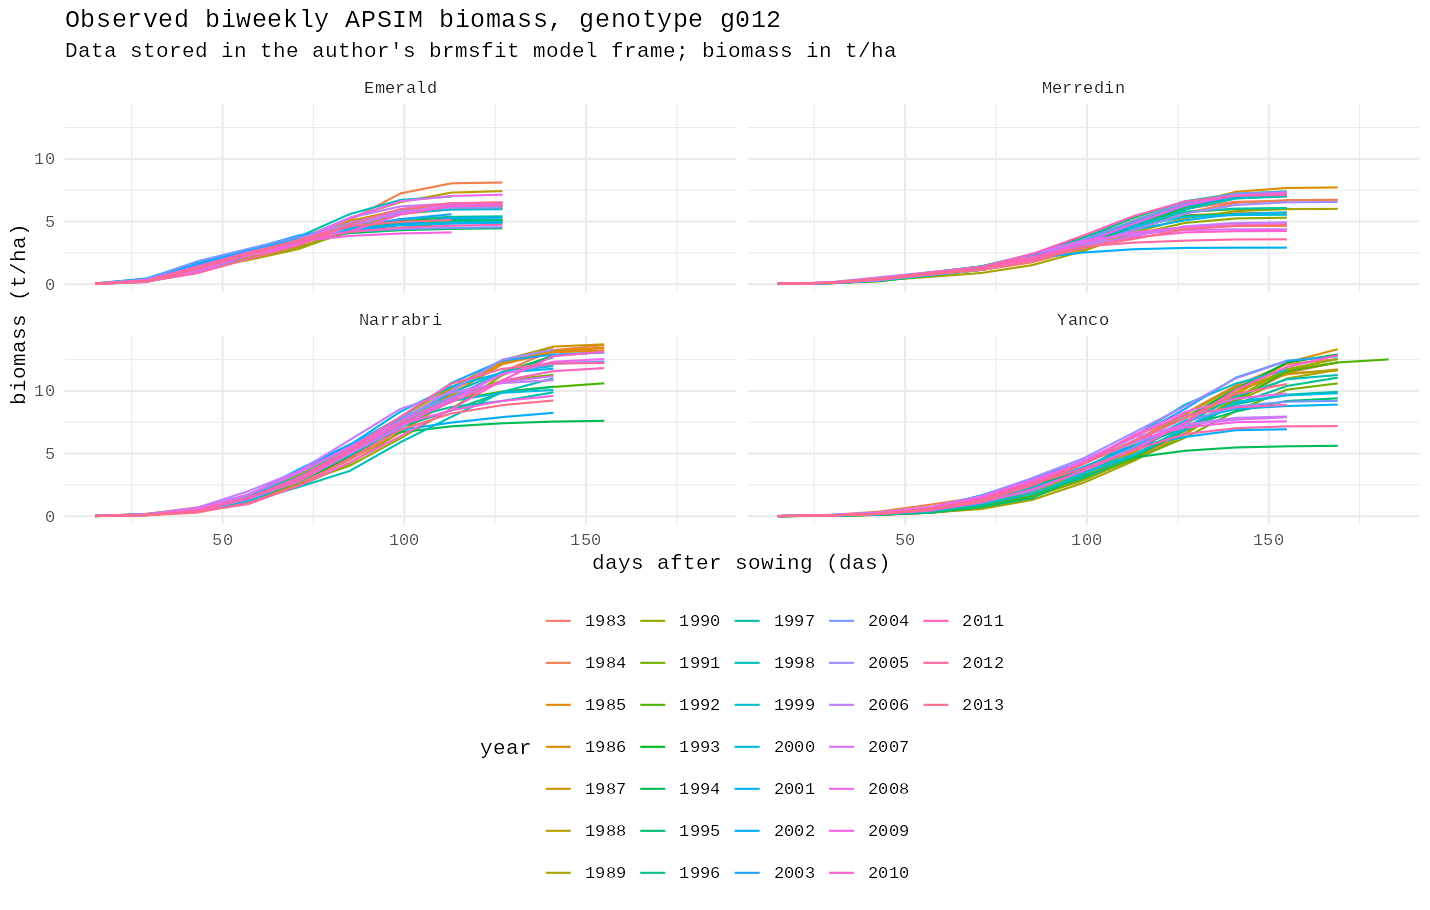

first rows of the model frame:


,biomass,Env,geno,das,dscaled
0,0.0222,Emerald_1983,g012,15,0.1
1,0.2829,Emerald_1983,g012,29,1.5
2,0.9986,Emerald_1983,g012,43,2.9
3,2.0100,Emerald_1983,g012,57,4.3
4,2.9704,Emerald_1983,g012,71,5.7
5,4.3438,Emerald_1983,g012,85,7.1
6,5.5849,Emerald_1983,g012,99,8.5
7,6.1640,Emerald_1983,g012,113,9.9
8,6.2325,Emerald_1983,g012,127,11.3
9,0.0227,Emerald_1983,g018,15,0.1


In [ ]:
import subprocess
def run_r(name, code):
    path = "/content/" + name
    open(path, "w").write(code)
    print("--- running " + name + " on Rscript ---", flush=True)
    r = subprocess.run(["Rscript", path], capture_output=True, text=True)
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr[-4000:])
        raise RuntimeError(name + " failed with exit code " + str(r.returncode))

R0 = r'''
## S0_input_preview.R
## Input preview: the exact biweekly modeling data stored inside the author's
## brmsfit object (fit_brms.RDS). Observed APSIM biomass curves for the author's
## reference genotype g012, one panel per location, coloured by year.
## (Author preview code: log_logistic_full_code.R lines 97-104, 156-163.)

suppressMessages(library(ggplot2))
options(warn = 1)
setwd("/content")
dir.create("figures", showWarnings = FALSE)
dir.create("outputs", showWarnings = FALSE)

cat("== loading fit_brms.RDS ==\n")
t0 <- Sys.time()
fit <- readRDS("/content/fit_brms.RDS")
cat("load seconds:", round(as.numeric(difftime(Sys.time(), t0, units = "secs")), 1), "\n")
stopifnot(class(fit) == "brmsfit")

d <- fit$data
cat("model data rows:", nrow(d), "\n")
cat("columns:", paste(names(d), collapse = ", "), "\n")
cat("genotypes:", nlevels(d$geno), " environments:", nlevels(d$Env), "\n")
stopifnot(nlevels(d$geno) == 48, nlevels(d$Env) == 124)
stopifnot(all(c("biomass", "Env", "geno", "dscaled") %in% names(d)))

## reconstruct das (days after sowing) and loc/year for readable plots
d$das <- (d$dscaled + 1.4) * 10
stopifnot(all(abs(d$das - round(d$das)) < 1e-6))
d$das <- round(d$das)
d$loc <- sub("_.*$", "", as.character(d$Env))
d$year <- sub("^[^_]+_", "", as.character(d$Env))
stopifnot(!any(grepl("_", d$year)))  # every Env name must be loc_year

ref_geno <- "g012"  # author's reference genotype (used for ET summaries)
stopifnot(ref_geno %in% levels(d$geno))
d1 <- d[d$geno == ref_geno, ]

cat("biomass range for", ref_geno, ":",
    round(min(d1$biomass), 3), "-", round(max(d1$biomass), 3),
    "(t/ha; raw APSIM values divided by 1000 by the author)\n")
cat("locations:", paste(sort(unique(d1$loc)), collapse = ", "), "\n")
cat("das values:", paste(sort(unique(d1$das)), collapse = ","), "\n")

write.csv(d[1:20, c("biomass", "Env", "geno", "das", "dscaled")],
          "/content/outputs/model_data_head.csv", row.names = FALSE)

p <- ggplot(d1, aes(x = das, y = biomass, colour = year)) +
  geom_line() +
  facet_wrap(~loc) +
  labs(title = paste("Observed biweekly APSIM biomass, genotype", ref_geno),
       subtitle = "Data stored in the author's brmsfit model frame; biomass in t/ha",
       x = "days after sowing (das)", y = "biomass (t/ha)", colour = "year") +
  theme_minimal(base_size = 12) +
  theme(legend.position = "bottom")
ggsave("/content/figures/input_preview.png", p, width = 11, height = 7,
       dpi = 130, bg = "white")
cat("saved figures/input_preview.png\n")
cat("S0-OK\n")
'''
run_r("S0_input_preview.R", R0)
from IPython.display import Image, display
display(Image(filename="/content/figures/input_preview.png", width=940))
import pandas as pd
print("first rows of the model frame:")
display(pd.read_csv("/content/outputs/model_data_head.csv"))

## 5. Posterior draw extraction and verification

**EN:** Extracts, per parameter (log-asymptote `logAsym`, log-midpoint `logtmid`, log-slope `logslope`): the 8000 draws × 5952 genotype:environment interaction effects, the genotype (48) and environment (124) random effects, and the population intercepts — directly from the stored fit's chains. Three verification gates run here: (a) assembly vs `rstan::summary` of the stored fit for intercepts and hierarchical SDs (< 1e-6); (b) condition-name mapping vs the model frame's factor levels; (c) a Kruschke-style literal recomputation of the author's per-cell loop on a 40-draw subset (< 1e-10). Then computes the adjusted genotype/environment effects, the per-cell 95% intervals of the adjusted interaction for `logAsym` (Table 2–3 analogue), and the genotype:environment / genotype SD and variance ratios.
**JP:** 著者のfitから事後分布サンプル（8000 draws）をパラメータごとに取り出し、(a) `rstan::summary`との照合、(b) 条件名とモデルフレーム水準の整合、(c) 著者のループ演算の40-draw再計算（<1e-10）の3重検証を行います。続いて調整済み遺伝子型・環境効果、`logAsym`の有意なG×Eセル（95%信用区間が0を含まない）、SD・分散比を計算します。（数分かかります）

In [ ]:
import subprocess
def run_r(name, code):
    path = "/content/" + name
    open(path, "w").write(code)
    print("--- running " + name + " on Rscript ---", flush=True)
    r = subprocess.run(["Rscript", path], capture_output=True, text=True)
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr[-4000:])
        raise RuntimeError(name + " failed with exit code " + str(r.returncode))

R1 = r'''
## S1_extract_verify.R
## Extract the posterior draws needed for all post-processing from the author's
## brmsfit and verify the draw assembly against rstan's own summaries.
## Author code: log_logistic_full_code.R lines 304-1209 (tidy_draws pipeline),
## here replaced by direct sim$samples assembly (matrix form; see notebook notes).

suppressMessages({library(brms); library(matrixStats)})
options(warn = 1)
setwd("/content")

cat("== loading fit_brms.RDS ==\n")
t0 <- Sys.time()
fit <- readRDS("/content/fit_brms.RDS")
cat("load seconds:", round(as.numeric(difftime(Sys.time(), t0, units = "secs")), 1), "\n")

sim <- fit$fit@sim
n_chains <- sim$chains
n_keep <- (sim$iter - sim$warmup) %/% sim$thin
pnames <- names(sim$samples[[1]])
n_draws <- n_chains * n_keep
cat("chains:", n_chains, "kept per chain:", n_keep, "total draws:", n_draws, "\n")

## Assemble a draws matrix (rows = draws, chain-major; order is irrelevant for
## every statistic computed here: means, medians, quantiles, k-means, correlations)
assemble <- function(pattern) {
  idx <- grep(pattern, pnames, value = TRUE)
  stopifnot(length(idx) > 0)
  m <- matrix(NA_real_, nrow = n_draws, ncol = length(idx), dimnames = list(NULL, idx))
  for (i in seq_len(n_chains)) {
    rows <- ((i - 1) * n_keep + 1L):(i * n_keep)
    for (j in seq_along(idx)) m[rows, j] <- as.numeric(sim$samples[[i]][[idx[j]]])
  }
  m
}

PARS <- c("logAsym", "logtmid", "logslope")

## ---- independent verification against rstan::summary (exact parameter names) ----
cat("== verifying assembly via rstan::summary (may take a few minutes) ==\n")
exact <- c(paste0("b_", PARS, "_Intercept"),
           grep("^r_geno__logAsym", pnames, value = TRUE),
           paste0("sd_geno__", PARS, "_Intercept"),
           paste0("sd_geno:Env__", PARS, "_Intercept"),
           paste0("sd_Env__", PARS, "_Intercept"))
stopifnot(length(exact) == 3 + 48 + 9)
t1 <- Sys.time()
sm <- rstan::summary(fit$fit, pars = exact, probs = c(0.025, 0.5, 0.975))$summary
cat("rstan::summary seconds:", round(as.numeric(difftime(Sys.time(), t1, units = "secs")), 1),
    "rows:", nrow(sm), "\n")
stopifnot(nrow(sm) == length(exact))

S <- assemble("^sd_")
stopifnot(ncol(S) == 9, nrow(S) == n_draws)
for (p in PARS) {
  b <- assemble(paste0("^b_", p, "_Intercept$"))
  stopifnot(ncol(b) == 1)
  stopifnot(abs(mean(b) - sm[paste0("b_", p, "_Intercept"), "mean"]) < 1e-6,
            abs(quantile(b, 0.025) - sm[paste0("b_", p, "_Intercept"), "2.5%"]) < 1e-6,
            abs(quantile(b, 0.975) - sm[paste0("b_", p, "_Intercept"), "97.5%"]) < 1e-6)
  for (sdn in c(paste0("sd_geno__", p, "_Intercept"),
                paste0("sd_geno:Env__", p, "_Intercept"),
                paste0("sd_Env__", p, "_Intercept"))) {
    stopifnot(abs(median(S[, sdn]) - sm[sdn, "50%"]) < 1e-6)
  }
  rm(b); invisible(gc())
}
cat("ASSEMBLY-VERIFIED against rstan::summary (b_ and sd_ parameters)\n")

## ---- per-parameter processing ----
res <- list(); geno_names <- NULL; Env_names <- NULL; geno_c <- NULL; Env_c <- NULL

for (p in PARS) {
  cat("== processing", p, "==\n")
  I <- assemble(paste0("^r_geno:Env__", p))
  G <- assemble(paste0("^r_geno__", p))
  E <- assemble(paste0("^r_Env__", p))
  b <- assemble(paste0("^b_", p, "_Intercept$"))
  stopifnot(ncol(I) == 48 * 124, ncol(G) == 48, ncol(E) == 124, ncol(b) == 1)

  glevels <- sub(paste0("^r_geno__", p, "\\["), "", colnames(G))
  glevels <- sub(",Intercept\\]$", "", glevels)
  elevels <- sub(paste0("^r_Env__", p, "\\["), "", colnames(E))
  elevels <- sub(",Intercept\\]$", "", elevels)
  stopifnot(!any(grepl("_", glevels)))
  if (is.null(geno_names)) {
    geno_names <- glevels; Env_names <- elevels
    stopifnot(identical(sort(glevels), sort(levels(fit$data$geno))))
    stopifnot(identical(sort(elevels), sort(levels(fit$data$Env))))
    stopifnot(all(grepl("^[^_]+_[^_]+$", elevels)))
  } else {
    stopifnot(identical(glevels, geno_names), identical(elevels, Env_names))
  }

  cn <- sub(paste0("^r_geno:Env__", p, "\\["), "", colnames(I))
  cn <- sub(",Intercept\\]$", "", cn)
  geno_c <- sub("_.*$", "", cn)          # first token = genotype code
  Env_c <- sub("^[^_]+_", "", cn)        # remainder = environment (loc_year)
  stopifnot(all(paste(geno_c, Env_c, sep = "_") == cn))

  ## Kruschke (2011) sec. 20.1.1 cell means, as in the author's loop:
  ## mu(g,e) = b + geno effect + Env effect + geno:Env interaction
  M_g <- model.matrix(~ 0 + factor(geno_c, levels = glevels))
  M_e <- model.matrix(~ 0 + factor(Env_c, levels = elevels))
  Ind_g <- sweep(M_g, 2, colSums(M_g), "/")   # mean over the 124 Envs
  Ind_e <- sweep(M_e, 2, colSums(M_e), "/")   # mean over the 48 genotypes
  Ig <- I %*% Ind_g
  Ie <- I %*% Ind_e
  grandI <- rowMeans(I)
  rG <- rowMeans(G); rE <- rowMeans(E)

  geno_prime <- sweep(G, 1, rG, "-") + Ig - grandI   # adjusted geno effect (draws x 48)
  Env_prime  <- sweep(E, 1, rE, "-") + Ie - grandI   # adjusted Env effect (draws x 124)
  colnames(geno_prime) <- glevels; colnames(Env_prime) <- elevels

  res[[paste0("geno_med_", p)]] <- apply(geno_prime, 2, median)
  res[[paste0("Env_med_", p)]]  <- apply(Env_prime, 2, median)

  if (p == "logAsym") {
    ## per-cell 95% credible intervals of the adjusted interaction genoEnv_prime
    ## (author lines 589-606); quantile() reproduces the author's type-7 quantiles
    lo <- numeric(ncol(I)); hi <- numeric(ncol(I))
    for (j in seq_len(ncol(I))) {
      adj <- I[, j] - Ig[, match(geno_c[j], glevels)] -
        Ie[, match(Env_c[j], elevels)] + grandI
      q <- quantile(adj, probs = c(0.025, 0.975), names = FALSE)
      lo[j] <- q[1]; hi[j] <- q[2]
    }
    intervals <- data.frame(geno = geno_c, Env = Env_c, lower = lo, upper = hi)
    intervals$significant <- as.integer(intervals$lower > 0 | intervals$upper < 0)
    res$intervals <- intervals
    cat("significant GxE cells (logAsym):", sum(intervals$significant),
        "of", nrow(intervals), "\n")

    ## Kruschke-style literal recomputation on a 40-draw subset, 3 cells,
    ## replicating the author's per-cell loop arithmetic (lines 539-579)
    set.seed(1)
    jsub <- sample(seq_len(ncol(I)), 3)
    dsub <- 1:40
    mu_grid <- matrix(NA_real_, length(dsub), ncol(I))
    for (j in seq_len(ncol(I))) {
      mu_grid[, j] <- b[dsub] + G[dsub, match(geno_c[j], glevels)] +
        E[dsub, match(Env_c[j], elevels)] + I[dsub, j]
    }
    ## literal marginals over the full grid
    m_geno <- vapply(glevels, function(g) {
      rowMeans(mu_grid[, geno_c == g, drop = FALSE])
    }, numeric(length(dsub)))
    m_Env <- vapply(elevels, function(e) {
      rowMeans(mu_grid[, Env_c == e, drop = FALSE])
    }, numeric(length(dsub)))
    grand_lit <- rowMeans(mu_grid)
    geno_prime_lit <- m_geno - grand_lit
    Env_prime_lit <- m_Env - grand_lit
    inter_lit <- lapply(jsub, function(j) {
      mu_grid[, j] - m_geno[, geno_c[j]] - m_Env[, Env_c[j]] + grand_lit
    })
    ## matrix-form results on the same subset
    geno_prime_sub <- geno_prime[dsub, ]
    Env_prime_sub <- Env_prime[dsub, ]
    stopifnot(max(abs(geno_prime_sub - geno_prime_lit)) < 1e-10,
              max(abs(Env_prime_sub - Env_prime_lit)) < 1e-10,
              max(abs(inter_lit[[1]] - (I[dsub, jsub[1]] -
                                          Ig[dsub, match(geno_c[jsub[1]], glevels)] -
                                          Ie[dsub, match(Env_c[jsub[1]], elevels)] +
                                          grandI[dsub]))) < 1e-10)
    cat("KRUSCHKE-SUBSET-CHECK-PASSED (40 draws, full 48x124 grid, 3 interaction cells)\n")
    rm(mu_grid, m_geno, m_Env)
  }

  rm(I, G, E, b, Ig, Ie, grandI, geno_prime, Env_prime, M_g, M_e, Ind_g, Ind_e)
  invisible(gc())
}

## ---- sd and variance ratios geno:Env / geno (author lines 387-491) ----
ratios <- data.frame()
for (p in PARS) {
  r <- S[, paste0("sd_geno:Env__", p, "_Intercept")] /
       S[, paste0("sd_geno__", p, "_Intercept")]
  ratios <- rbind(ratios,
                  data.frame(parameter = p, kind = "sd", ratio = r),
                  data.frame(parameter = p, kind = "variance", ratio = r^2))
}
res$ratios <- ratios
qsum <- aggregate(ratio ~ parameter + kind, data = ratios,
                  FUN = function(x) round(quantile(x, c(0.025, 0.5, 0.975)), 3))
cat("sd/variance ratio summary:\n"); print(qsum)

res$geno_names <- geno_names
res$Env_names <- Env_names
saveRDS(res, "/content/res_main.rds")
cat("saved res_main.rds\n")
cat("S1-OK\n")
'''
run_r("S1_extract_verify.R", R1)

--- running S1_extract_verify.R on Rscript ---


== loading fit_brms.RDS ==
load seconds: 33.6 
chains: 4 kept per chain: 2000 total draws: 8000 
== verifying assembly via rstan::summary (may take a few minutes) ==
rstan::summary seconds: 226 rows: 60 
ASSEMBLY-VERIFIED against rstan::summary (b_ and sd_ parameters)
== processing logAsym ==
significant GxE cells (logAsym): 2173 of 5952 
KRUSCHKE-SUBSET-CHECK-PASSED (40 draws, full 48x124 grid, 3 interaction cells)
== processing logtmid ==
== processing logslope ==
sd/variance ratio summary:
  parameter     kind ratio.2.5% ratio.50% ratio.97.5%
1   logAsym       sd      0.600     0.746       0.913
2  logslope       sd      0.001     0.025       0.084
3   logtmid       sd      0.211     0.267       0.325
4   logAsym variance      0.360     0.557       0.834
5  logslope variance      0.000     0.001       0.007
6   logtmid variance      0.045     0.071       0.106
saved res_main.rds
S1-OK



## 6. Variance decomposition, environment types and G×E frequencies

**EN:** Three author results from the verified draws:
- **SD/variance ratios** (`geno:Env / geno`): how much genotype-specific sensitivity to environment adds beyond main genotype differences (author figures `sd_ratios_*`, `var_ratios_*`). The paper reports the asymptote SD ratio "between 0.6 and 0.9" — our interval is checked against that quote in section 8.
- **ETs:** k-means (k=3) on the 124 environments × posterior medians of adjusted Env effects, with the author's seed (`5678123`), scaling and relabeling; medoid environments labelled on a pairs-style scatter matrix.
- **Significant G×E frequencies** for `logAsym`: percentage of environments with a significant adjusted interaction per genotype, and of genotypes per location×year (Tables 2–3 analogue).
**JP:** SD・分散比（分散分解）、環境型（ET）クラスタリング（著者と同じシード・再ラベル付け）、`logAsym`の有意G×E頻度（表2–3相当）を作成します。

--- running S2_et_freq.R on Rscript ---


cluster sizes: 44/46/34 
scaled cluster centers (after relabeling):
     logAsym    logtmid   logslope
1 -0.2911800  0.1362363  0.9031060
2  1.0083073  0.8368621 -0.1460687
3 -0.9873593 -1.3085309 -0.9711031
ET medoid environments: Merredin_1995, Yanco_2003, Emerald_1996 
locations: Emerald, Merredin, Narrabri, Yanco 
significant interaction cells by location:
  location n_sig_cells
1  Emerald         534
2 Merredin         422
3 Narrabri         586
4    Yanco         631
saved res_et.rds, figures and CSVs
S2-OK



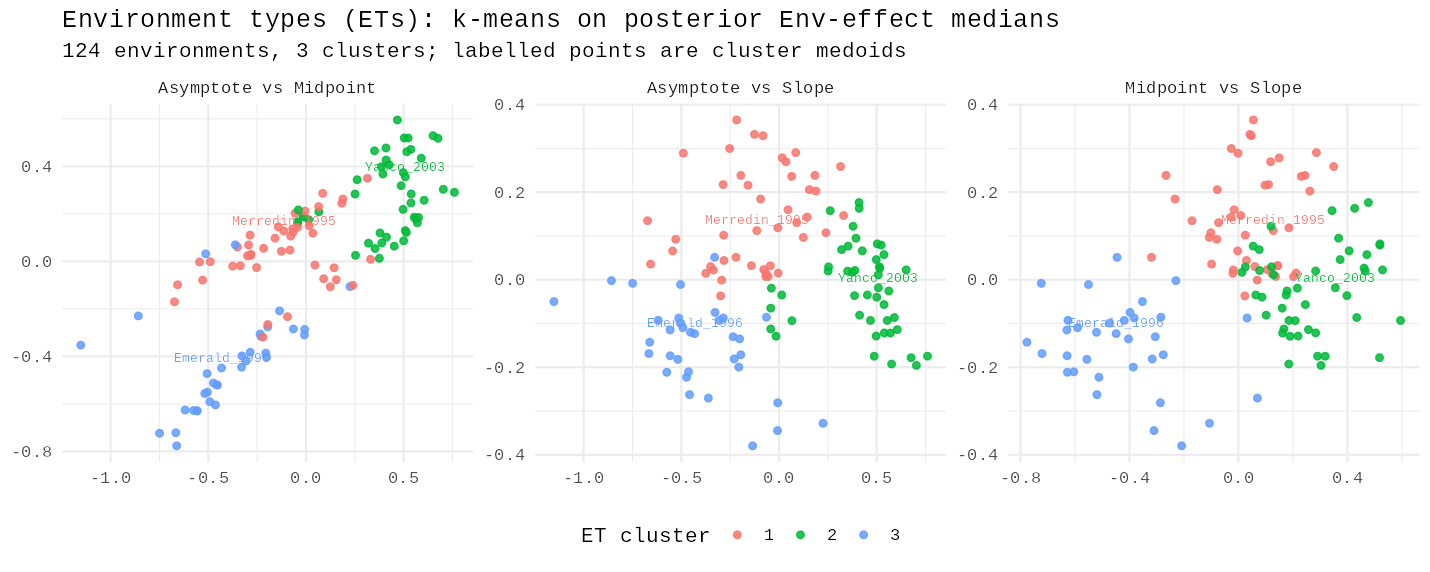

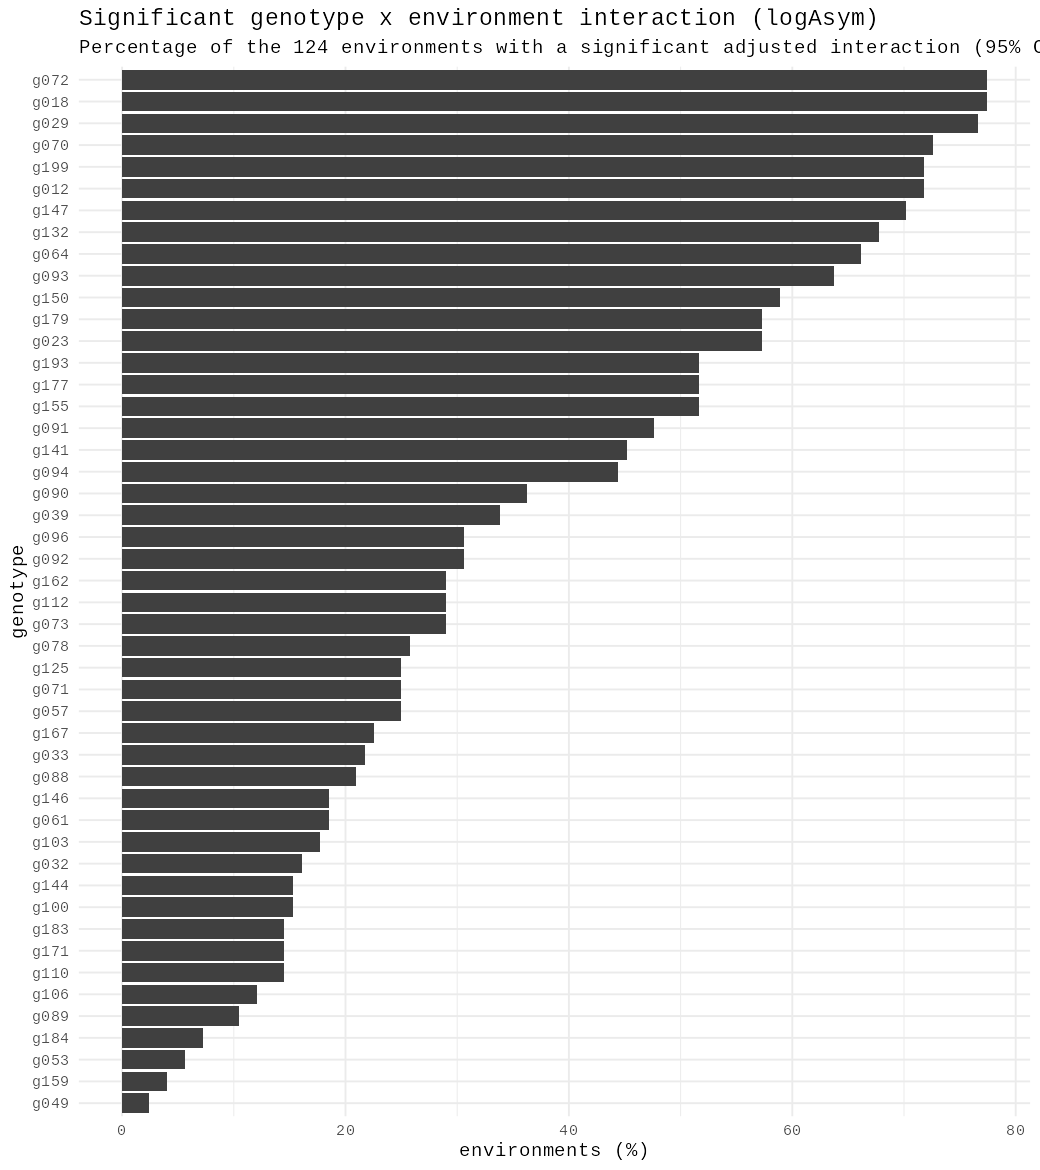

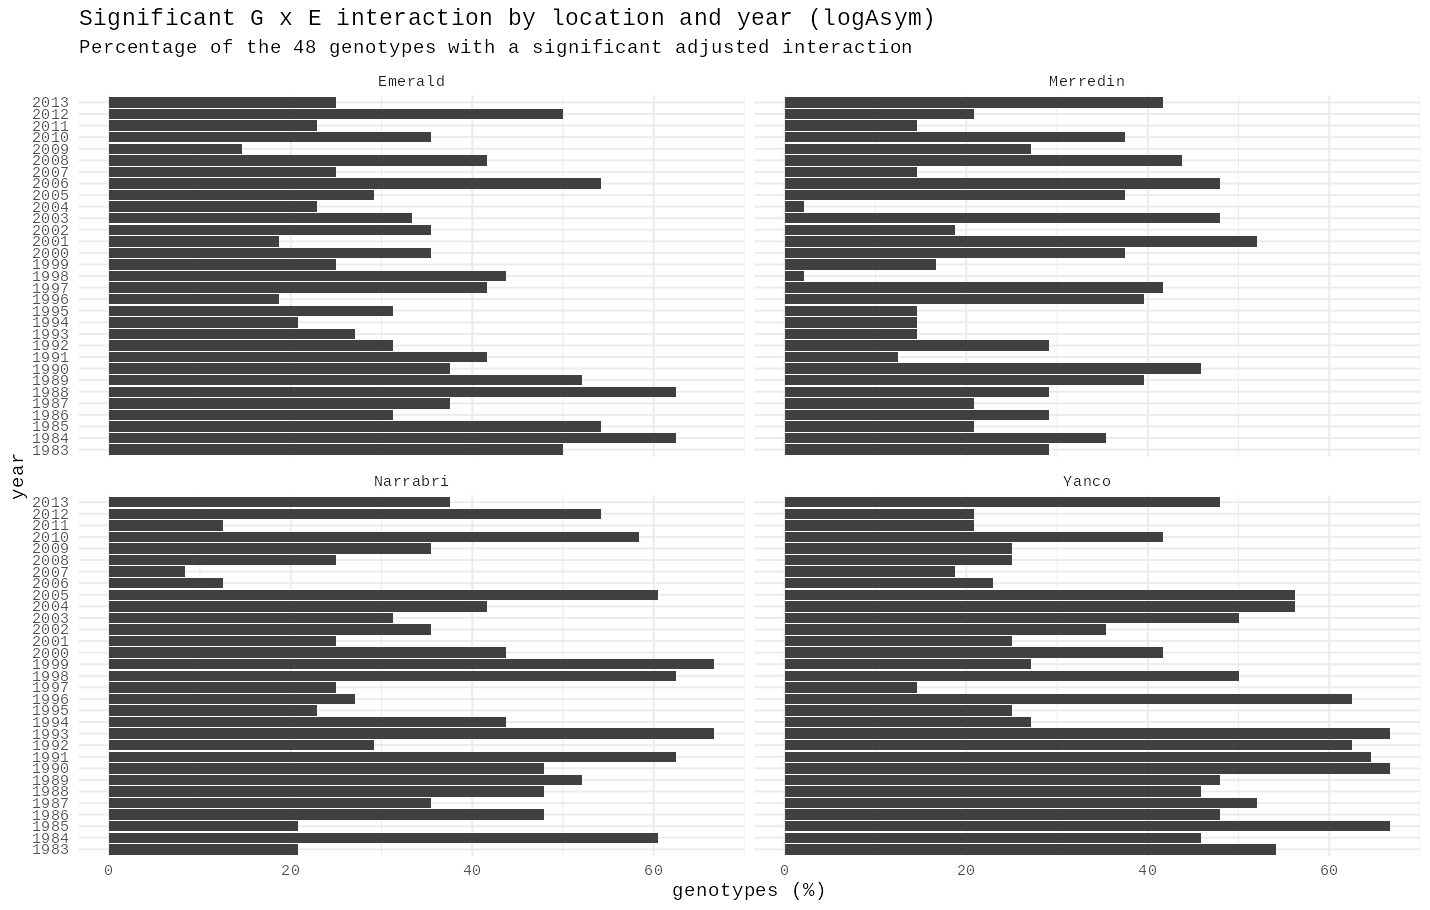

ET assignments (head):


,trial,cluster,medoid
0,Emerald_1983,3,False
1,Emerald_1984,3,False
2,Emerald_1985,3,False
3,Emerald_1986,3,False
4,Emerald_1987,3,False
5,Emerald_1988,3,False
6,Emerald_1989,3,False
7,Emerald_1990,3,False


significant GxE cells per location:


,location,year,n_genos,pct
0,Emerald,1983,24,50.000000
1,Merredin,1983,14,29.166667
2,Narrabri,1983,10,20.833333
3,Yanco,1983,26,54.166667
4,Emerald,1984,30,62.500000
5,Merredin,1984,17,35.416667
6,Narrabri,1984,29,60.416667
7,Yanco,1984,22,45.833333
8,Emerald,1985,26,54.166667
9,Merredin,1985,10,20.833333


In [ ]:
import subprocess
def run_r(name, code):
    path = "/content/" + name
    open(path, "w").write(code)
    print("--- running " + name + " on Rscript ---", flush=True)
    r = subprocess.run(["Rscript", path], capture_output=True, text=True)
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr[-4000:])
        raise RuntimeError(name + " failed with exit code " + str(r.returncode))

R2 = r'''
## S2_et_freq.R
## Envirotypes (ETs): k-means clustering of the 124 environments on the posterior
## medians of the adjusted Env effects (author lines 1213-1401), cluster pairs
## plot, medoid environments, and the significant G x E interaction frequency
## figures (author lines 589-729, Tables 2-3 analogues).

suppressMessages(library(ggplot2))
options(warn = 1)
setwd("/content")

res <- readRDS("/content/res_main.rds")

Env_pars0 <- cbind(logAsym = res$Env_med_logAsym,
                   logtmid = res$Env_med_logtmid,
                   logslope = res$Env_med_logslope)
rownames(Env_pars0) <- res$Env_names
stopifnot(dim(Env_pars0) == c(124, 3))

## k-means exactly as the author: same seed, scaling, centers, nstart
set.seed(5678123)
kmeans3 <- kmeans(scale(Env_pars0), centers = 3, iter.max = 1000, nstart = 100)

## author's cluster relabeling (tied to their kmeans run; means printed below)
cluster_labels <- kmeans3$cluster
cluster_labels[kmeans3$cluster == 1] <- 3
cluster_labels[kmeans3$cluster == 2] <- 2
cluster_labels[kmeans3$cluster == 3] <- 1

cat("cluster sizes:", paste(as.numeric(table(cluster_labels)), collapse = "/"), "\n")
cat("scaled cluster centers (after relabeling):\n")
km_centers <- scale(Env_pars0)
ctr <- aggregate(km_centers, by = list(cluster = cluster_labels), FUN = mean)
print(ctr[order(ctr$cluster), 2:4])

## medoids per cluster: member minimizing the sum of standardized Euclidean
## distances to the other members (GDAtools::medoids definition used by the author)
dm <- as.matrix(dist(scale(Env_pars0)))
medoid_of_cluster <- function(cl) {
  members <- which(cluster_labels == cl)
  sums <- rowSums(dm[members, members, drop = FALSE])
  members[which.min(sums)]
}
et_medoids <- vapply(1:3, medoid_of_cluster, integer(1))
names(et_medoids) <- paste("cluster", 1:3)
cat("ET medoid environments:", paste(rownames(Env_pars0)[et_medoids], collapse = ", "), "\n")

loc_year <- strsplit(rownames(Env_pars0), "_")
ep <- as.data.frame(Env_pars0)
names(ep) <- c("Asymptote", "Midpoint", "Slope")
ep$trial <- rownames(Env_pars0)
ep$cluster <- factor(cluster_labels)
ep$loc <- vapply(loc_year, `[`, "", 1)
ep$year <- vapply(loc_year, `[`, "", 2)
ep$medoid <- rownames(Env_pars0) %in% rownames(Env_pars0)[et_medoids]

## pairs-style scatter matrix (ggplot analogue of the author's ggpairs figure)
combos <- data.frame(x = c("Asymptote", "Asymptote", "Midpoint"),
                     y = c("Slope", "Midpoint", "Slope"))
long <- do.call(rbind, lapply(seq_len(nrow(combos)), function(i) {
  data.frame(panel = paste(combos$x[i], "vs", combos$y[i]),
             x = ep[[combos$x[i]]], y = ep[[combos$y[i]]],
             cluster = ep$cluster, medoid = ep$medoid, trial = ep$trial,
             xl = combos$x[i], yl = combos$y[i])
}))
p_pairs <- ggplot(long, aes(x, y, colour = cluster)) +
  geom_point(size = 1.6, alpha = 0.85) +
  geom_text(data = subset(long, medoid), aes(label = trial), size = 2.6,
            vjust = -0.7, show.legend = FALSE) +
  facet_wrap(~panel, scales = "free") +
  labs(title = "Environment types (ETs): k-means on posterior Env-effect medians",
       subtitle = "124 environments, 3 clusters; labelled points are cluster medoids",
       x = NULL, y = NULL, colour = "ET cluster") +
  theme_minimal(base_size = 12) +
  theme(legend.position = "bottom")
ggsave("/content/figures/et_pairs.png", p_pairs, width = 11, height = 4.4,
       dpi = 130, bg = "white")

## significant G x E interaction frequencies for logAsym (author lines 611-729)
iv <- res$intervals
iv$location <- sub("_.*$", "", iv$Env)
iv$year <- sub("^[^_]+_", "", iv$Env)
stopifnot(nrow(iv) == 5952, !any(grepl("_", iv$year)))

sig_geno <- aggregate(significant ~ geno, data = iv[iv$significant == 1, ], FUN = length)
names(sig_geno) <- c("genotype", "n_envs")
sig_geno$pct <- 100 * sig_geno$n_envs / 124
sig_geno <- sig_geno[order(sig_geno$n_envs), ]
sig_geno$genotype <- factor(sig_geno$genotype, levels = sig_geno$genotype)
write.csv(sig_geno, "/content/outputs/gxe_geno_frequency.csv", row.names = FALSE)

p_geno <- ggplot(sig_geno, aes(genotype, pct)) +
  geom_col(fill = "grey25") +
  coord_flip() +
  labs(title = "Significant genotype x environment interaction (logAsym)",
       subtitle = "Percentage of the 124 environments with a significant adjusted interaction (95% CI excluding 0)",
       x = "genotype", y = "environments (%)") +
  theme_minimal(base_size = 11)
ggsave("/content/figures/gxe_geno_freq.png", p_geno, width = 8, height = 9,
       dpi = 130, bg = "white")

sig_ly <- aggregate(significant ~ location + year,
                    data = iv[iv$significant == 1, ], FUN = length)
names(sig_ly) <- c("location", "year", "n_genos")
sig_ly$pct <- 100 * sig_ly$n_genos / 48
write.csv(sig_ly, "/content/outputs/gxe_locyear_frequency.csv", row.names = FALSE)
cat("locations:", paste(sort(unique(sig_ly$location)), collapse = ", "), "\n")

p_ly <- ggplot(sig_ly, aes(year, pct)) +
  geom_col(fill = "grey25") +
  coord_flip() +
  facet_wrap(~location) +
  labs(title = "Significant G x E interaction by location and year (logAsym)",
       subtitle = "Percentage of the 48 genotypes with a significant adjusted interaction",
       x = "year", y = "genotypes (%)") +
  theme_minimal(base_size = 11)
ggsave("/content/figures/gxe_locyear_freq.png", p_ly, width = 11, height = 7,
       dpi = 130, bg = "white")

## frequency by location (author lines 613-616 printed table)
sig_loc <- aggregate(significant ~ location, data = iv[iv$significant == 1, ], FUN = length)
names(sig_loc) <- c("location", "n_sig_cells")
cat("significant interaction cells by location:\n"); print(sig_loc)

res_et <- list(cluster_labels = cluster_labels,
               kmeans_centers = kmeans3$centers,
               et_medoids = rownames(Env_pars0)[et_medoids],
               Env_pars0 = Env_pars0)
saveRDS(res_et, "/content/res_et.rds")

et_out <- data.frame(trial = rownames(Env_pars0), cluster = cluster_labels)
et_out$medoid <- et_out$trial %in% res_et$et_medoids
write.csv(et_out, "/content/outputs/et_assignments.csv", row.names = FALSE)
cat("saved res_et.rds, figures and CSVs\n")
cat("S2-OK\n")
'''
run_r("S2_et_freq.R", R2)
from IPython.display import Image, display
display(Image(filename="/content/figures/et_pairs.png", width=940))
display(Image(filename="/content/figures/gxe_geno_freq.png", width=700))
display(Image(filename="/content/figures/gxe_locyear_freq.png", width=940))
import pandas as pd
print("ET assignments (head):")
display(pd.read_csv("/content/outputs/et_assignments.csv").head(8))
print("significant GxE cells per location:")
display(pd.read_csv("/content/outputs/gxe_locyear_frequency.csv").head(10))

## 7. Fitted curves for the ET medoid environments

**EN:** For each ET medoid environment, the fitted log-logistic curve per genotype is computed **in closed form from the posterior draws**: cell mean log-parameters `b + geno effect + Env effect + geno:Env interaction`, then `y(x) = Asym / (1 + (x/tmid)^(−slope))` with `Asym = exp(·)`, on the author's 25-point grid; ribbons are pointwise 95% credible bands over draws. The author obtained the same posterior-mean curves via `brms::conditional_effects(method = "posterior_epred")`, which requires compiling the Stan model — not possible here without the Stan backend, so the mathematically identical quantity is computed directly (labelled adaptation). Observed biweekly biomass points are overlaid from the model frame.
**JP:** ETメドイド環境3か所について、遺伝子型ごとのロジスティック成長曲線を事後サンプルから解析的に計算します（著者は`conditional_effects`を使用しますが、これはStanバックエンドが必要なため同等量を直接計算。適応として明記）。観測点を重ねて表示します。

--- running S3_et_curves.R on Rscript ---


ET medoid environments: Merredin_1995, Yanco_2003, Emerald_1996 
== loading fit_brms.RDS ==
logAsym cell draws: 8000 144 
logtmid cell draws: 8000 144 
logslope cell draws: 8000 144 
curve summary rows: 3600 
observed points for medoid envs: 1505 
saved figures/et_medoid_curves.png
S3-OK



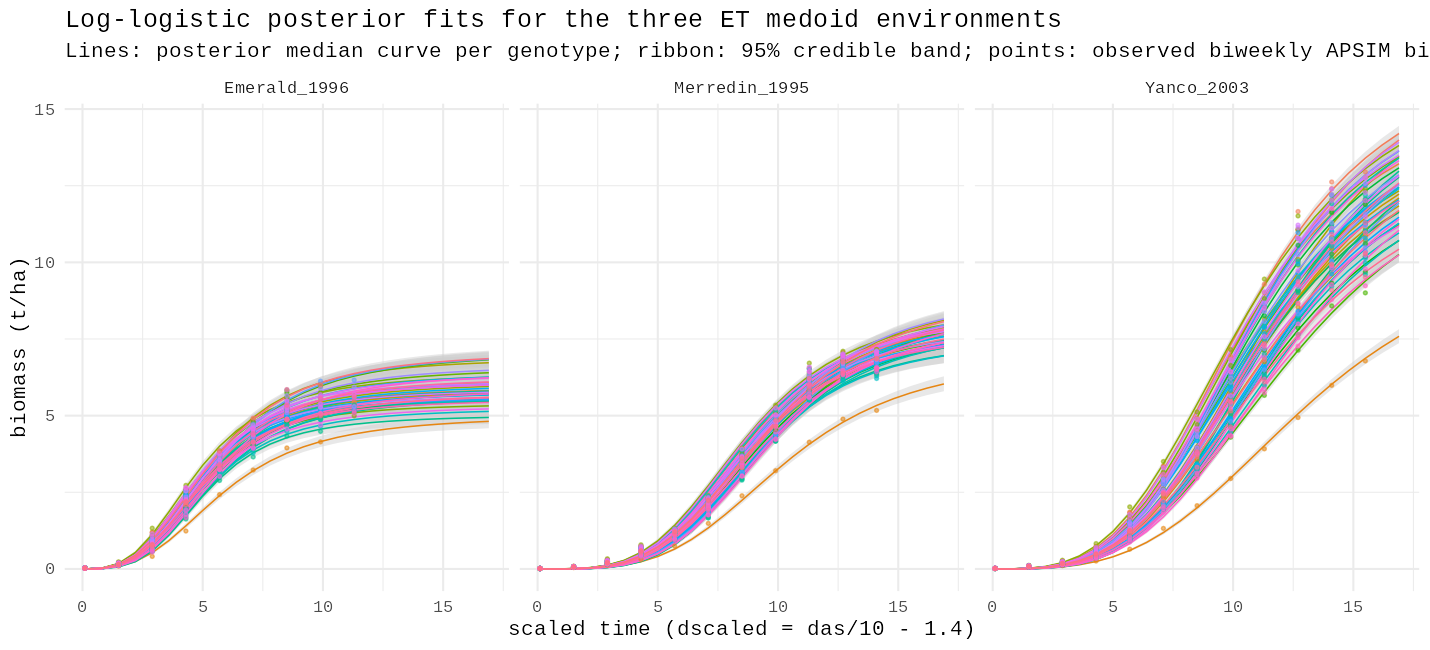

In [ ]:
import subprocess
def run_r(name, code):
    path = "/content/" + name
    open(path, "w").write(code)
    print("--- running " + name + " on Rscript ---", flush=True)
    r = subprocess.run(["Rscript", path], capture_output=True, text=True)
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr[-4000:])
        raise RuntimeError(name + " failed with exit code " + str(r.returncode))

R3 = r'''
## S3_et_curves.R
## Fitted log-logistic growth curves for the three ET medoid environments,
## computed directly from the posterior draws (author lines 1597-1655 used
## brms::conditional_effects, which requires compiling the Stan model; the
## posterior mean curve of this model is the cell-mean log-logistic function,
## so the same quantity is computed here in closed form from the draws).
## Observed biweekly points are overlaid from the model frame in the fit.

suppressMessages(library(ggplot2))
options(warn = 1)
setwd("/content")

res_et <- readRDS("/content/res_et.rds")
medoids <- res_et$et_medoids
cat("ET medoid environments:", paste(medoids, collapse = ", "), "\n")

cat("== loading fit_brms.RDS ==\n")
fit <- readRDS("/content/fit_brms.RDS")
d <- fit$data

sim <- fit$fit@sim
n_chains <- sim$chains; n_keep <- (sim$iter - sim$warmup) %/% sim$thin
pnames <- names(sim$samples[[1]])
n_draws <- n_chains * n_keep
assemble_pattern <- function(pattern) {
  idx <- grep(pattern, pnames, value = TRUE)
  stopifnot(length(idx) > 0)
  m <- matrix(NA_real_, nrow = n_draws, ncol = length(idx), dimnames = list(NULL, idx))
  for (i in seq_len(n_chains)) {
    rows <- ((i - 1) * n_keep + 1L):(i * n_keep)
    for (j in seq_along(idx)) m[rows, j] <- as.numeric(sim$samples[[i]][[idx[j]]])
  }
  m
}

med_re <- paste(medoids, collapse = "|")
PARS <- c("logAsym", "logtmid", "logslope")
cell_draws <- list()  # per parameter: draws x (48 genotypes x 3 medoid Envs)

for (p in PARS) {
  I <- assemble_pattern(paste0("^r_geno:Env__", p, "\\[[^,]*(", med_re, "),Intercept\\]$"))
  G <- assemble_pattern(paste0("^r_geno__", p))
  E <- assemble_pattern(paste0("^r_Env__", p))
  b <- assemble_pattern(paste0("^b_", p, "_Intercept$"))
  cn <- sub(paste0("^r_geno:Env__", p, "\\["), "", colnames(I))
  cn <- sub(",Intercept\\]$", "", cn)
  geno_c <- sub("_.*$", "", cn); Env_c <- sub("^[^_]+_", "", cn)
  stopifnot(ncol(I) == 48 * 3, setequal(unique(Env_c), medoids))
  glevels <- sub(paste0("^r_geno__", p, "\\["), "", colnames(G))
  glevels <- sub(",Intercept\\]$", "", glevels)
  elevels <- sub(paste0("^r_Env__", p, "\\["), "", colnames(E))
  elevels <- sub(",Intercept\\]$", "", elevels)
  ## cell mean of the log-parameter per draw: b + geno effect + Env effect + interaction
  mu <- sweep(I, 1, as.numeric(b), "+") +
    G[, match(geno_c, glevels), drop = FALSE] +
    E[, match(Env_c, elevels), drop = FALSE]
  cell_draws[[p]] <- mu
  colnames(cell_draws[[p]]) <- cn
  cat(p, "cell draws:", dim(mu), "\n")
  rm(I, G, E, b, mu); invisible(gc())
}

## posterior curves on a 25-point grid (author used resolution = 25)
xg <- seq(min(d$dscaled), max(d$dscaled), length.out = 25)
conds <- colnames(cell_draws$logAsym)
curve_summary <- do.call(rbind, lapply(conds, function(cd) {
  g <- sub("_.*$", "", cd); env <- sub("^[^_]+_", "", cd)
  Asym <- exp(cell_draws$logAsym[, cd])
  tmid <- exp(cell_draws$logtmid[, cd])
  slope <- exp(cell_draws$logslope[, cd])
  ydraws <- matrix(NA_real_, n_draws, length(xg))
  for (k in seq_along(xg)) {
    ydraws[, k] <- Asym / (1 + (xg[k] / tmid)^(-slope))
  }
  data.frame(geno = g, Env = env, dscaled = xg,
             fit_median = apply(ydraws, 2, median),
             fit_lo = apply(ydraws, 2, quantile, probs = 0.025, names = FALSE),
             fit_hi = apply(ydraws, 2, quantile, probs = 0.975, names = FALSE))
}))
cat("curve summary rows:", nrow(curve_summary), "\n")

obs <- d[as.character(d$Env) %in% medoids, ]
obs$Env <- as.character(obs$Env)
obs$geno <- as.character(obs$geno)
cat("observed points for medoid envs:", nrow(obs), "\n")

curve_summary$geno <- factor(curve_summary$geno, levels = sort(unique(curve_summary$geno)))
obs$geno <- factor(obs$geno, levels = levels(curve_summary$geno))

p_curves <- ggplot(curve_summary, aes(x = dscaled, group = geno)) +
  geom_ribbon(aes(ymin = fit_lo, ymax = fit_hi), fill = "grey80", alpha = 0.45) +
  geom_line(aes(y = fit_median, colour = geno), linewidth = 0.4) +
  geom_point(data = obs, aes(x = dscaled, y = biomass, colour = geno),
             size = 0.7, alpha = 0.55, show.legend = FALSE) +
  facet_wrap(~Env) +
  labs(title = "Log-logistic posterior fits for the three ET medoid environments",
       subtitle = "Lines: posterior median curve per genotype; ribbon: 95% credible band; points: observed biweekly APSIM biomass (t/ha)",
       x = "scaled time (dscaled = das/10 - 1.4)", y = "biomass (t/ha)") +
  theme_minimal(base_size = 12) +
  theme(legend.position = "none")
ggsave("/content/figures/et_medoid_curves.png", p_curves, width = 11, height = 5,
       dpi = 130, bg = "white")
cat("saved figures/et_medoid_curves.png\n")

## export the fitted curves for the medoid genotype g012 as an example CSV
ex <- subset(curve_summary, geno == "g012")
write.csv(ex, "/content/outputs/et_medoid_curves_g012.csv", row.names = FALSE)
cat("S3-OK\n")
'''
run_r("S3_et_curves.R", R3)
from IPython.display import Image, display
display(Image(filename="/content/figures/et_medoid_curves.png", width=940))

## 8. Correlations with APSIM physiological parameters

**EN:** Pearson correlations (with 95% CI) between the posterior medians of the adjusted genotype main effects and 8 APSIM physiological parameters (`fr_lf_sen_rate`, `grains_per_gram_stem`, `ll_modifier`, `max_grain_size`, `photop_sens`, `potential_grain_filling_rate`, `tt_floral_initiation`, `vern_sens`), for the 48 sampled genotypes — the author's Figure 10 analogue. Rows are aligned by genotype name (the author relied on identical row order; see the adaptation note in the title cell).
**JP:** 調整済み遺伝子型主効果の事後中央値とAPSIM生理パラメータ8種のピアソン相関（95%CI）を計算します（著者Fig.10相当）。行は遺伝子型名で明示的に整合させました。

--- running S4_corr.R on Rscript ---


Parameters_D1 dims: 199 13 
genotype order aligned; n = 48 
correlation estimates:
                       phys_par   mod_par        corr
1                fr_lf_sen_rate Asymptote  0.02234669
2          grains_per_gram_stem Asymptote  0.04140661
3                   ll_modifier Asymptote -0.86773941
4                max_grain_size Asymptote -0.04144892
5                   photop_sens Asymptote -0.13556832
6  potential_grain_filling_rate Asymptote -0.20169709
7          tt_floral_initiation Asymptote -0.20977605
8                     vern_sens Asymptote  0.19665515
9                fr_lf_sen_rate  Midpoint -0.01824760
10         grains_per_gram_stem  Midpoint  0.17606111
11                  ll_modifier  Midpoint -0.20329308
12               max_grain_size  Midpoint  0.27184112
13                  photop_sens  Midpoint  0.22327587
14 potential_grain_filling_rate  Midpoint  0.14250517
15         tt_floral_initiation  Midpoint  0.13788188
16                    vern_sens  Midpoint  0.06698616

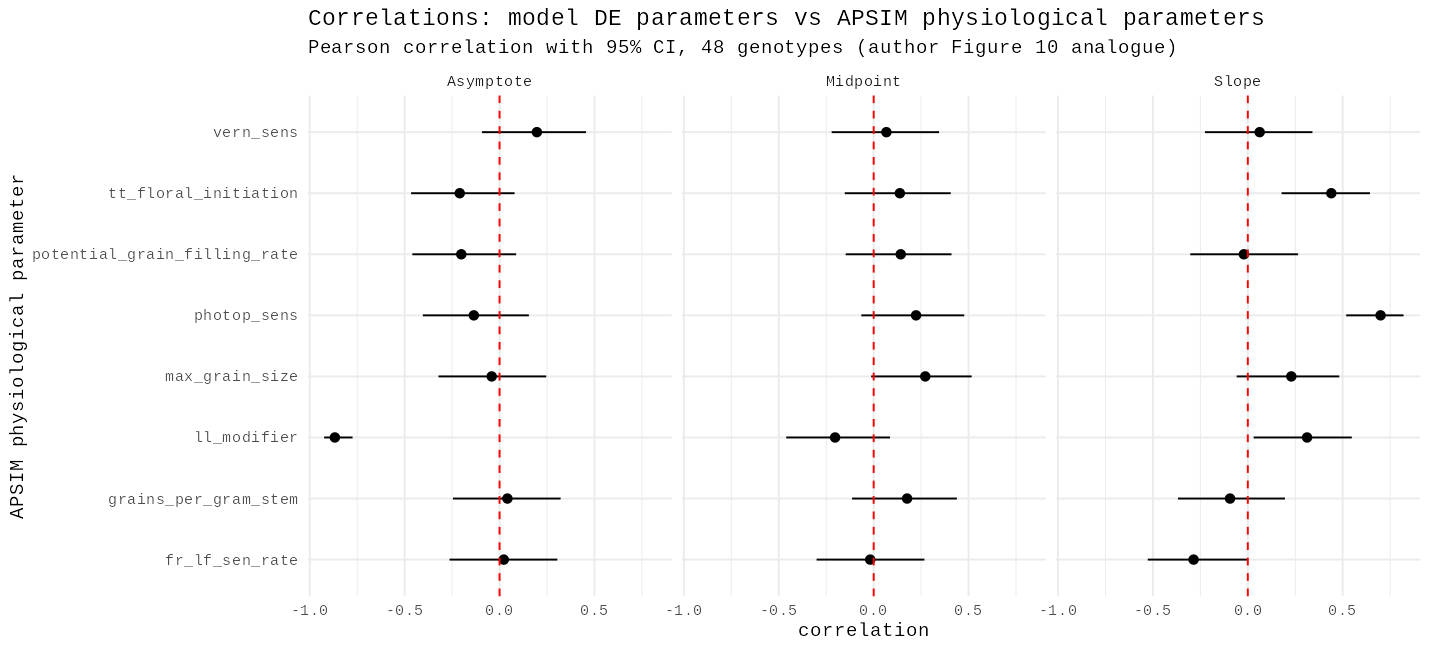

correlation table:


,phys_par,mod_par,corr,lower,upper
0,fr_lf_sen_rate,Asymptote,0.022347,-0.263461,0.304548
1,grains_per_gram_stem,Asymptote,0.041407,-0.245618,0.321756
2,ll_modifier,Asymptote,-0.867739,-0.924046,-0.774582
3,max_grain_size,Asymptote,-0.041449,-0.321794,0.245578
4,photop_sens,Asymptote,-0.135568,-0.404136,0.154518
5,potential_grain_filling_rate,Asymptote,-0.201697,-0.459498,0.087449
6,tt_floral_initiation,Asymptote,-0.209776,-0.466127,0.079072
7,vern_sens,Asymptote,0.196655,-0.092657,0.455347
8,fr_lf_sen_rate,Midpoint,-0.018248,-0.300823,0.267273
9,grains_per_gram_stem,Midpoint,0.176061,-0.113765,0.438271


In [ ]:
import subprocess
def run_r(name, code):
    path = "/content/" + name
    open(path, "w").write(code)
    print("--- running " + name + " on Rscript ---", flush=True)
    r = subprocess.run(["Rscript", path], capture_output=True, text=True)
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr[-4000:])
        raise RuntimeError(name + " failed with exit code " + str(r.returncode))

R4 = r'''
## S4_corr.R
## Correlations between the adjusted genotype main effects (posterior medians)
## and the APSIM physiological parameters (author lines 1105-1209, Figure 10
## analogue). Parameters_D1.csv is the author-provided APSIM parameter table
## (repo copy, MD5-verified against the figshare record).

suppressMessages(library(ggplot2))
options(warn = 1)
setwd("/content")

res <- readRDS("/content/res_main.rds")
geno_med <- cbind(logAsym = res$geno_med_logAsym,
                  logtmid = res$geno_med_logtmid,
                  logslope = res$geno_med_logslope)
rownames(geno_med) <- res$geno_names
stopifnot(dim(geno_med) == c(48, 3))

## author used read_csv(..., quote = "'"); replicate with base R
Parameters_D1 <- read.csv("/content/Parameters_D1.csv", quote = "'", stringsAsFactors = FALSE)
cat("Parameters_D1 dims:", dim(Parameters_D1), "\n")
phys_pars <- c("fr_lf_sen_rate", "grains_per_gram_stem", "ll_modifier",
               "max_grain_size", "photop_sens", "potential_grain_filling_rate",
               "tt_floral_initiation", "vern_sens")
stopifnot(all(phys_pars %in% names(Parameters_D1)), "Genotype" %in% names(Parameters_D1))

p2 <- Parameters_D1[, c("Genotype", phys_pars)]
names(p2)[1] <- "genotype"
p2 <- p2[p2$genotype %in% rownames(geno_med), ]
stopifnot(nrow(p2) == 48)
## align both tables by genotype name (the author relied on identical row order;
## we sort explicitly, which preserves the pairing when both are name-sorted)
p2 <- p2[order(p2$genotype), ]
gm <- geno_med[order(rownames(geno_med)), ]
stopifnot(identical(p2$genotype, rownames(gm)))
cat("genotype order aligned; n =", nrow(p2), "\n")

mod_pars <- c(logAsym = "Asymptote", logtmid = "Midpoint", logslope = "Slope")
par_corr <- do.call(rbind, lapply(names(mod_pars), function(mp) {
  do.call(rbind, lapply(phys_pars, function(pp) {
    ct <- cor.test(p2[[pp]], gm[, mp])
    data.frame(phys_par = pp, mod_par = unname(mod_pars[mp]),
               corr = as.numeric(ct$estimate),
               lower = as.numeric(ct$conf.int[1]),
               upper = as.numeric(ct$conf.int[2]))
  }))
}))
write.csv(par_corr, "/content/outputs/apsim_correlations.csv", row.names = FALSE)
cat("correlation estimates:\n"); print(par_corr[, c("phys_par", "mod_par", "corr")])

par_corr$mod_par <- factor(par_corr$mod_par, levels = c("Asymptote", "Midpoint", "Slope"))
par_corr$phys_par <- factor(par_corr$phys_par, levels = phys_pars)

p_corr <- ggplot(par_corr, aes(x = phys_par, y = corr)) +
  geom_pointrange(aes(ymin = lower, ymax = upper), size = 0.35) +
  geom_hline(yintercept = 0, colour = "red", linetype = "dashed") +
  coord_flip() +
  facet_wrap(~mod_par, ncol = 3) +
  labs(title = "Correlations: model DE parameters vs APSIM physiological parameters",
       subtitle = "Pearson correlation with 95% CI, 48 genotypes (author Figure 10 analogue)",
       x = "APSIM physiological parameter", y = "correlation") +
  theme_minimal(base_size = 11)
ggsave("/content/figures/par_corr.png", p_corr, width = 11, height = 5,
       dpi = 130, bg = "white")
cat("saved figures/par_corr.png and outputs/apsim_correlations.csv\n")
cat("S4-OK\n")
'''
run_r("S4_corr.R", R4)
from IPython.display import Image, display
display(Image(filename="/content/figures/par_corr.png", width=940))
import pandas as pd
print("correlation table:")
display(pd.read_csv("/content/outputs/apsim_correlations.csv"))

## 9. Run summary and saved outputs

**EN:** Collects the exported CSV tables and the key numbers produced above, prints the provenance record (source commit, hashes), and lists all artifacts written under `/content/figures` and `/content/outputs`. These files are created on the Colab VM at runtime — download them from the notebook's file browser if you want to keep them.
**JP:** 生成されたCSV・図と主要な数値、 provenance（コミット・ハッシュ）を一覧化します。ファイルはColab VM上の `/content` にあります。

In [ ]:
import hashlib, os, glob
import pandas as pd
print("provenance:")
print("  author repo: gugushvili/dynamic_phenotypes @ d1b1fc11a5c9b4b1ddfd52f251a96ffb46d5d284 (GPL-3.0)")
print("  fit_brms.RDS sha256:", hashlib.sha256(open("/content/fit_brms.RDS", "rb").read(1 << 24)).hexdigest()[:16], "... (full hash asserted at download)")
print("  paper: bioRxiv 10.64898/2026.11.05.764527 v1")
print()
sig_geno = pd.read_csv("/content/outputs/gxe_geno_frequency.csv")
et = pd.read_csv("/content/outputs/et_assignments.csv")
corr = pd.read_csv("/content/outputs/apsim_correlations.csv")
ly = pd.read_csv("/content/outputs/gxe_locyear_frequency.csv")
print("key numbers from this run:")
print("  genotypes with >=1 significant GxE env (logAsym):", len(sig_geno), "of 48")
print("  max significant-env share for one genotype: %.1f%%" % sig_geno.pct.max())
print("  ET cluster sizes:", list(et.cluster.value_counts().sort_index()))
print("  ET medoid environments:", sorted(et[et.medoid].trial.tolist()))
print("  strongest |corr| vs APSIM params: %.2f" % corr["corr"].abs().max())
print()
print("saved artifacts:")
for f in sorted(glob.glob("/content/figures/*") + glob.glob("/content/outputs/*")):
    print(" ", f, os.path.getsize(f), "bytes")

provenance:
  author repo: gugushvili/dynamic_phenotypes @ d1b1fc11a5c9b4b1ddfd52f251a96ffb46d5d284 (GPL-3.0)
  fit_brms.RDS sha256: 1b7ba00036616fa7 ... (full hash asserted at download)
  paper: bioRxiv 10.64898/2026.11.05.764527 v1

key numbers from this run:
  genotypes with >=1 significant GxE env (logAsym): 48 of 48
  max significant-env share for one genotype: 77.4%
  ET cluster sizes: [44, 46, 34]
  ET medoid environments: ['Emerald_1996', 'Merredin_1995', 'Yanco_2003']
  strongest |corr| vs APSIM params: 0.87

saved artifacts:
  /content/figures/et_medoid_curves.png 215006 bytes
  /content/figures/et_pairs.png 113900 bytes
  /content/figures/gxe_geno_freq.png 78499 bytes
  /content/figures/gxe_locyear_freq.png 91181 bytes
  /content/figures/input_preview.png 150314 bytes
  /content/figures/par_corr.png 59689 bytes
  /content/outputs/apsim_correlations.csv 2088 bytes
  /content/outputs/et_assignments.csv 2876 bytes
  /content/outputs/et_medoid_curves_g012.csv 5918 bytes
  /conte

## 10. Interpretation, scope and validation record

**What you just reproduced** (all quantities from the author's own published posterior, one CPU runtime):
- The variance decomposition: genotype×environment SD ratios per growth parameter, with credible intervals — the paper's key evidence that G×E acts on the *shape* of biomass growth, not only the asymptote. The paper states the asymptote ratio "was between 0.6 and 0.9" (§3.1); compare with the printed interval in section 5.
- Significant-interaction frequencies per genotype and per location×year for the log-asymptote (Tables 2–3 analogue).
- Three environment types with medoid environments and fitted curves with observed data (Figures 7-ish visual analogue).
- Model-vs-APSIM-parameter correlations (Figure 10 analogue).

**What this does NOT establish:** the MCMC fit itself (loaded, not refitted), any dataset-level accuracy claim, and the posterior-predictive/residual diagnostics (omitted; need the Stan backend + 488 MB dataset). A single executed notebook is not a verification of the paper's published conclusions beyond the computed quantities above.

**Determinism notes:** k-means labels use the author's seed and relabeling; cluster labels are tied to that run (cluster means are printed so labels stay interpretable). Draw assembly was verified against `rstan::summary` and a literal Kruschke-style recomputation.

**References**
- Gugushvili, S. et al. (2026). A hierarchical Bayesian model for dynamic phenotypes in multi-environment trials with genotype by environment interaction. bioRxiv 2026.11.05.764527.
- Code: https://github.com/gugushvili/dynamic_phenotypes (commit `d1b1fc11a5c9b4b1ddfd52f251a96ffb46d5d284`, GPL-3.0).
- Data: Bustos-Korts et al., APSIM wheat simulated genotypes, figshare doi:10.6084/m9.figshare.24843705.v1 (CC BY 4.0).
- Bürkner, P.-C. (2017). brms: An R Package for Bayesian Multilevel Models Using Stan. JSS 80(1).
- Kruschke, J. K. (2011). Doing Bayesian Data Analysis, §20.1.1 (hierarchical shrinkage / cell-means post-processing).
- 日本語メモ: 本ノートブックは著者の学習済みモデルを読み込み、分散分解・G×E頻度・環境型・APSIMパラメータ相関を再現します。フィッティング自体（数日規模）は範囲外です。